In [4]:
import numpy as np
import matplotlib.pyplot as plt

from PyMPDATA import Options, ScalarField, VectorField, Stepper, Solver
from PyMPDATA.boundary_conditions import Constant

from open_atmos_jupyter_utils import show_anim

from tqdm.auto import tqdm

plt.rcParams.update({
    'mathtext.fontset': 'cm',
    'font.family': 'STIXGeneral',
    'font.size': 12
})

In [5]:
T0 = 240.0
Tm = 50.0 
alpha = 0.12

LX = 30.0
LY= 4.0   

DX = 0.1
DT = 0.008

TOTAL_TIME = 40.0
SAVE_INTERVAL = 1.0

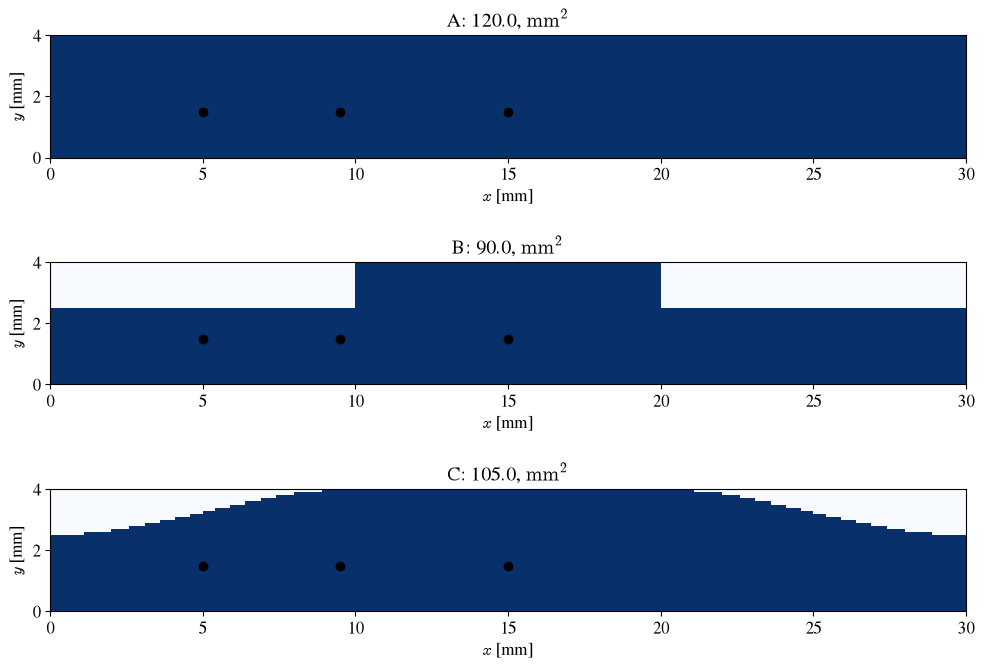

In [17]:
def smoothstep(q):
    return 3*q**2 - 2*q**3


def create_masks(dx):

    dy = dx

    nx = round(LX / dx)
    ny = round(LY / dy)

    dx = LX / nx
    dy = LY / ny

    x = (np.arange(nx) + 0.5) * dx
    y = (np.arange(ny) + 0.5) * dy

    h_max = 4.0
    h_min = 2.5
    h_diff = h_max - h_min

    h_A = np.full(nx, h_max)


    h_B = np.full(nx, h_min)
    boss_B = (x >= 10) & (x < 20)
    h_B[boss_B] = h_max


    h_C = np.full(nx, h_min)

    left = x < 10.0
    q = x[left] / 10.0
    h_C[left] = h_min + h_diff * smoothstep(q)

    center = (x >= 10.0) & (x < 20.0)
    h_C[center] = h_max

    right = x >= 20.0
    q = (x[right] - 20.0) / 10.0
    h_C[right] = h_min + h_diff * ( 1 - smoothstep(q) )
    

    Y = y[None, :]

    mask_A = Y < h_A[:, None]
    mask_B = Y < h_B[:, None]
    mask_C = Y < h_C[:, None]

    masks = {
        "A": mask_A,
        "B": mask_B,
        "C": mask_C
    }

    return x, y, masks, dx, dy


def plot_masks(x, y, masks):

    fig, axes = plt.subplots(3, 1, figsize=(10, 7))
    dx = LX / len(x)
    dy = LY / len(y)

    x_points = [5, 9.5, 15]
    y_ponits = [1.5, 1.5, 1.5]

    for ax, (name, mask) in zip(axes, masks.items()):

        ax.imshow(mask.T, origin="lower", extent=(0, LX, 0, LY), cmap="Blues", vmin=0, vmax=1)
        ax.set_aspect('equal', adjustable='box')

        ax.scatter(x_points, y_ponits, color='k')

        area = np.sum(mask) * dx * dy
        ax.set_title(rf"{name}: {area}, $\text{{mm}}^2$")
        ax.set_xlabel(r"$x$ [mm]")
        ax.set_ylabel(r"$y$ [mm]")

    plt.tight_layout()
    plt.savefig("figs/geometries.pdf", format="pdf", bbox_inches="tight")
    plt.savefig("figs/geometries.svg", format="svg", bbox_inches="tight")
    plt.show()


x, y, masks, dx, dy = create_masks(DX)
plot_masks(x, y, masks)



In [7]:
def simulate(mask, dx, dy, dt, total_time, save_interval):

    nx, ny = mask.shape

    n_steps_float = total_time / dt
    save_steps_float = save_interval / dt
    n_steps = round(n_steps_float)
    steps_per_save = round(save_interval / dt)

    if not np.isclose(n_steps_float, n_steps):
        raise ValueError("total_time must be divisible by dt")

    if not np.isclose(save_steps_float, steps_per_save):
        raise ValueError("save_interval must be divisible by dt")

    if n_steps % steps_per_save != 0:
        raise ValueError("Total time must be divisible by save_interval")

    T_initial = np.full((nx, ny), Tm, dtype=np.float64)
    T_initial[mask] = T0

    options = Options(n_iters=2, non_zero_mu_coeff=True)
    halo = options.n_halo

    temperature = ScalarField(data=T_initial, halo=halo,boundary_conditions=(Constant(Tm), Constant(Tm)))

    velocity = VectorField(data=(np.zeros((nx + 1, ny)), np.zeros((nx, ny + 1))), halo=halo, boundary_conditions=(Constant(0.0), Constant(0.0)))

    stepper = Stepper(options=options, grid=(nx, ny))

    solver = Solver(stepper=stepper, advectee=temperature, advector=velocity)

    mu_coeff = (alpha * dt / dx**2, alpha * dt / dy**2)

    print(f"Grid: {nx} x {ny}")
    print(f"DX = {dx} mm, DY = {dy} mm")
    print(f"DT = {dt} s")
    print(f"Diffusion coefficients: {mu_coeff}")

    frames = []
    frame_times = []

    def record_state(time, T):
        frame = T.astype(np.float32)
        frame[~mask] = np.nan

        frames.append(frame)
        frame_times.append(time)

    T = solver.advectee.get()
    T[~mask] = Tm

    record_state(0.0, T)

    for step in tqdm(range(1, n_steps + 1), desc="MPDATA"):

        solver.advance(n_steps=1, mu_coeff=mu_coeff)

        T = solver.advectee.get()
        T[~mask] = Tm

        if step % steps_per_save == 0:

            current_time = step * dt
            record_state(current_time, T)

    T_final = solver.advectee.get().copy()

    return {
        "final": T_final,
        "frames": frames,
        "frame_times": frame_times,
        "mu_coeff": mu_coeff,
        "dx" : dx,
        "dy": dy,
        "dt" : dt
    }


In [ ]:
def make_animation(name, result):

    frames = result["frames"]
    times = result["frame_times"]

    def plot_frame(frame):

        T = frames[frame]

        fig, ax = plt.subplots(figsize=(10, 2.5))

        im = ax.imshow(np.ma.masked_invalid(T.T), origin="lower", extent=(0, LX, 0, LY), aspect="equal", vmin=Tm, vmax=T0)

        ax.set_xlabel("x [mm]")
        ax.set_ylabel("y [mm]")

        ax.set_title(f"{name} | t = {times[frame]:.1f} s")

        fig.colorbar(im, ax=ax, label=r"Temperatura [$^\circ$C]")

        fig.tight_layout()

        return fig

    filename = f"results/animations/geometry_{name}.gif"

    show_anim(plot_func=plot_frame, frame_range=range(len(frames)), duration=0.08, loop=0, gif_file=filename)

In [9]:
def get_point_temperature(frames, dx_mm, dy_mm, points):

    nx, ny = frames[0].shape

    x_centers = (np.arange(nx) + 0.5) * dx_mm
    y_centers = (np.arange(ny) + 0.5) * dy_mm

    temperatures = np.zeros((len(frames), len(points)))

    for j, (xp, yp) in enumerate(points):

        if not (x_centers[0] <= xp <= x_centers[-1]):
            raise ValueError(f"Point x={xp} outside grid")

        if not (y_centers[0] <= yp <= y_centers[-1]):
            raise ValueError(f"Point y={yp} outside grid")

        ix1 = np.clip(np.searchsorted(x_centers, xp), 1, nx - 1)
        iy1 = np.clip(np.searchsorted(y_centers, yp), 1, ny - 1)

        ix0 = ix1 - 1
        iy0 = iy1 - 1

        wx = (xp - x_centers[ix0]) / (x_centers[ix1] - x_centers[ix0])
        wy = (yp - y_centers[iy0]) / (y_centers[iy1] - y_centers[iy0])

        for i, frame in enumerate(frames):

            f00 = frame[ix0, iy0]
            f10 = frame[ix1, iy0]
            f01 = frame[ix0, iy1]
            f11 = frame[ix1, iy1]

            temperatures[i, j] = ((1 - wx) * (1 - wy) * f00 + wx * (1 - wy) * f10 + (1 - wx) * wy * f01 + wx * wy * f11)

    return temperatures


Simulation: A
Grid: 300 x 40
DX = 0.1 mm, DY = 0.1 mm
DT = 0.008 s
Diffusion coefficients: (0.09599999999999999, 0.09599999999999999)


MPDATA:   0%|          | 0/5000 [00:00<?, ?it/s]


Simulation: B
Grid: 300 x 40
DX = 0.1 mm, DY = 0.1 mm
DT = 0.008 s
Diffusion coefficients: (0.09599999999999999, 0.09599999999999999)


MPDATA:   0%|          | 0/5000 [00:00<?, ?it/s]


Simulation: C
Grid: 300 x 40
DX = 0.1 mm, DY = 0.1 mm
DT = 0.008 s
Diffusion coefficients: (0.09599999999999999, 0.09599999999999999)


MPDATA:   0%|          | 0/5000 [00:00<?, ?it/s]


Generating animation: A



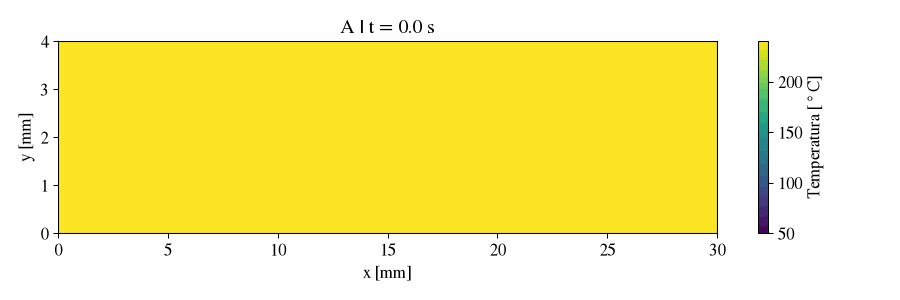

HTML(value="<a href='.\\geaometry_A.gif' target='_blank'>.\\geaometry_A.gif</a><br>")


Generating animation: B



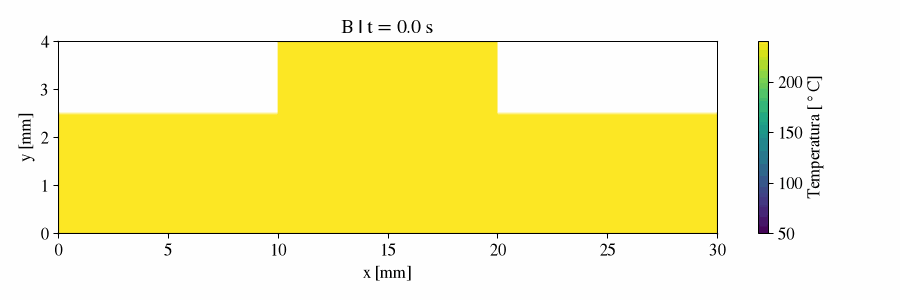

HTML(value="<a href='.\\geaometry_B.gif' target='_blank'>.\\geaometry_B.gif</a><br>")


Generating animation: C



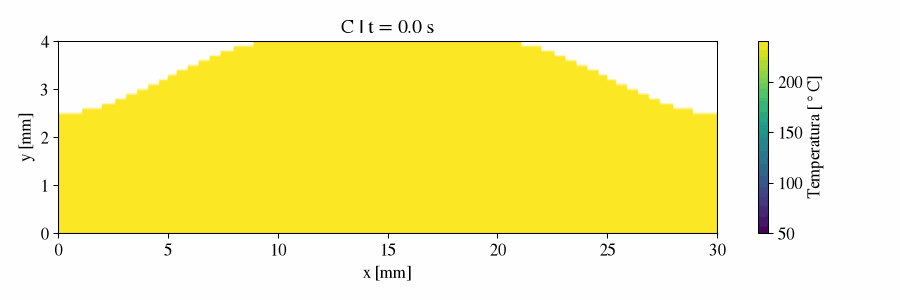

HTML(value="<a href='.\\geaometry_C.gif' target='_blank'>.\\geaometry_C.gif</a><br>")

In [ ]:
results = {}

for name, mask in masks.items():
    print("\nSimulation:", name)
    results[name] = simulate(mask=mask, dx=dx, dy=dy, dt=DT, total_time=TOTAL_TIME, save_interval=SAVE_INTERVAL)



Generating animation: A



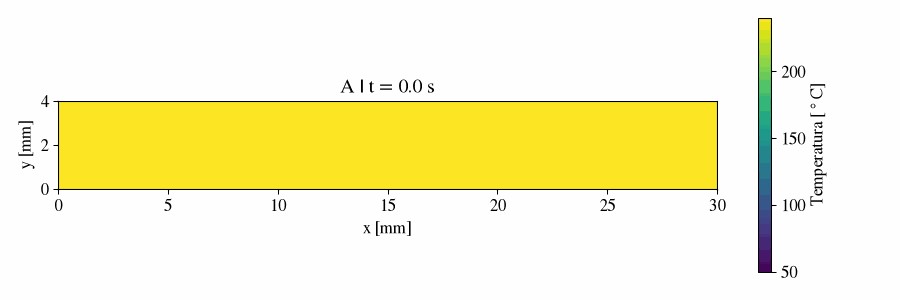

HTML(value="<a href='.\\geometry_A.gif' target='_blank'>.\\geometry_A.gif</a><br>")


Generating animation: B



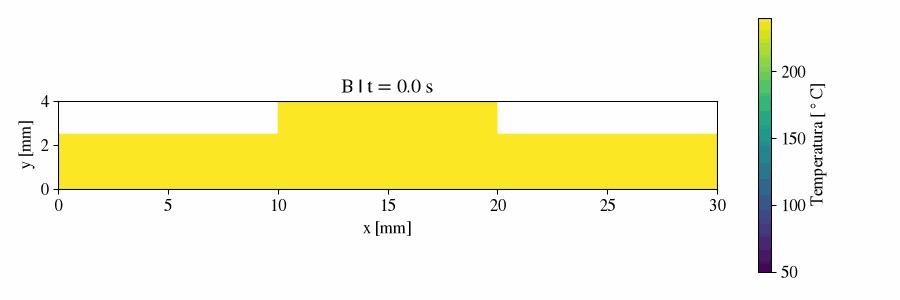

HTML(value="<a href='.\\geometry_B.gif' target='_blank'>.\\geometry_B.gif</a><br>")


Generating animation: C


In [ ]:
for name, result in results.items():
    print("\nGenerating animation:", name)
    make_animation(name, result)

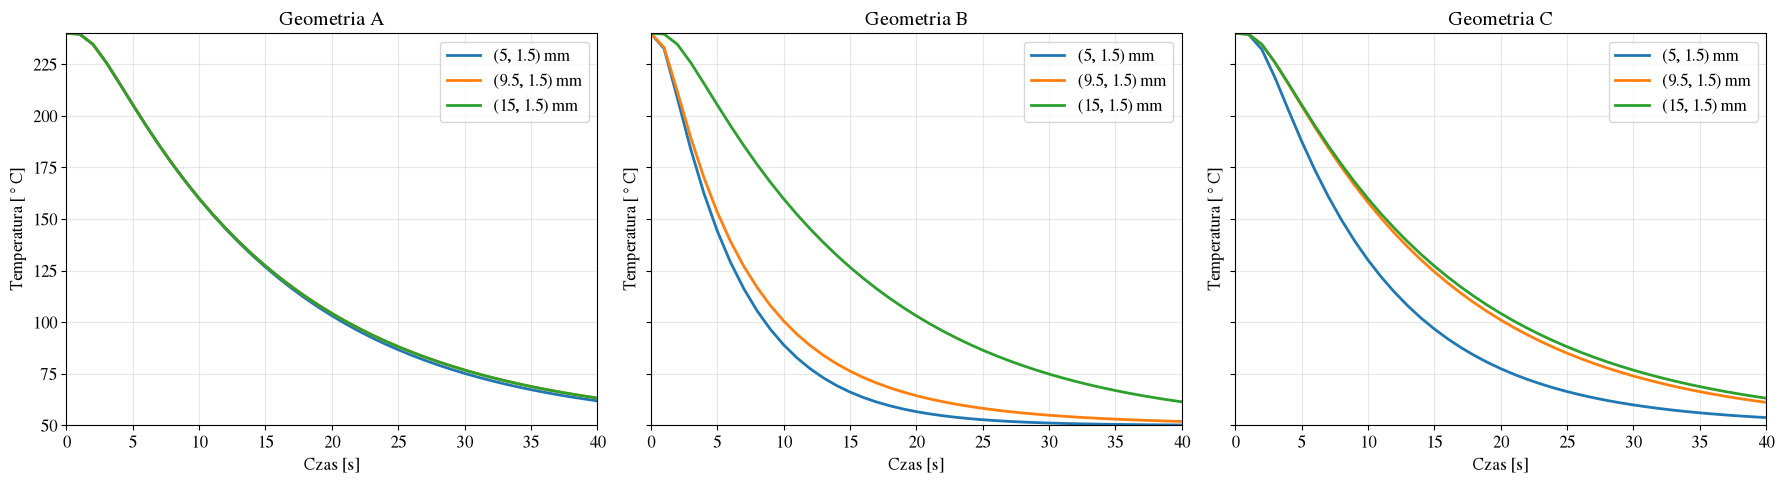

In [20]:
measurement_points = [(5.0, 1.5), (9.5, 1.5), (15.0, 1.5)]

point_labels = ["(5, 1.5) mm", "(9.5, 1.5) mm", "(15, 1.5) mm"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

for ax, (name, result) in zip(axes, results.items()):

    temperatures = get_point_temperature(result["frames"], DX, DX, measurement_points)

    for i in range(len(measurement_points)):
        ax.plot(result["frame_times"], temperatures[:, i], label=point_labels[i], linewidth=2)

    ax.set_title(f"Geometria {name}")
    ax.set_xlabel("Czas [s]")
    ax.set_ylabel(r"Temperatura [$^\circ$C]")
    ax.legend()

    ax.set_xlim(0, TOTAL_TIME)
    ax.set_ylim(Tm, T0)

    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("figs/point_measurements.pdf", format="pdf", bbox_inches="tight")
plt.savefig("figs/point_measurements.svg", format="svg", bbox_inches="tight")
plt.show()

In [12]:
dx_array = [0.2, 0.1, 0.075, 0.05]
dt_array = [0.008, 0.004, 0.002, 0.001]

dt_const = 0.001
dx_const = 0.1

results_x = []
results_t = []

for dx_test in dx_array:
    _, _, masks_x, dx_actual, dy_actual, = create_masks(dx_test)
    results_x.append( simulate(mask=masks_x['A'], dx=dx_actual, dy=dy_actual, dt=dt_const, total_time=TOTAL_TIME, save_interval=SAVE_INTERVAL) )


for dt_test in dt_array:
    _, _, masks_t, _, _, = create_masks(dx_const)
    results_t.append( simulate(mask=masks_t['A'], dx=dx_const, dy=dy, dt=dt_test, total_time=TOTAL_TIME, save_interval=SAVE_INTERVAL) )

Grid: 150 x 20
DX = 0.2 mm, DY = 0.2 mm
DT = 0.001 s
Diffusion coefficients: (0.0029999999999999996, 0.0029999999999999996)


MPDATA:   0%|          | 0/40000 [00:00<?, ?it/s]

Grid: 300 x 40
DX = 0.1 mm, DY = 0.1 mm
DT = 0.001 s
Diffusion coefficients: (0.011999999999999999, 0.011999999999999999)


MPDATA:   0%|          | 0/40000 [00:00<?, ?it/s]

Grid: 400 x 53
DX = 0.075 mm, DY = 0.07547169811320754 mm
DT = 0.001 s
Diffusion coefficients: (0.021333333333333336, 0.021067500000000003)


MPDATA:   0%|          | 0/40000 [00:00<?, ?it/s]

... (6 outputs left out)

Grid: 300 x 40
DX = 0.1 mm, DY = 0.1 mm
DT = 0.002 s
Diffusion coefficients: (0.023999999999999997, 0.023999999999999997)


MPDATA:   0%|          | 0/20000 [00:00<?, ?it/s]

Grid: 300 x 40
DX = 0.1 mm, DY = 0.1 mm
DT = 0.001 s
Diffusion coefficients: (0.011999999999999999, 0.011999999999999999)


MPDATA:   0%|          | 0/40000 [00:00<?, ?it/s]

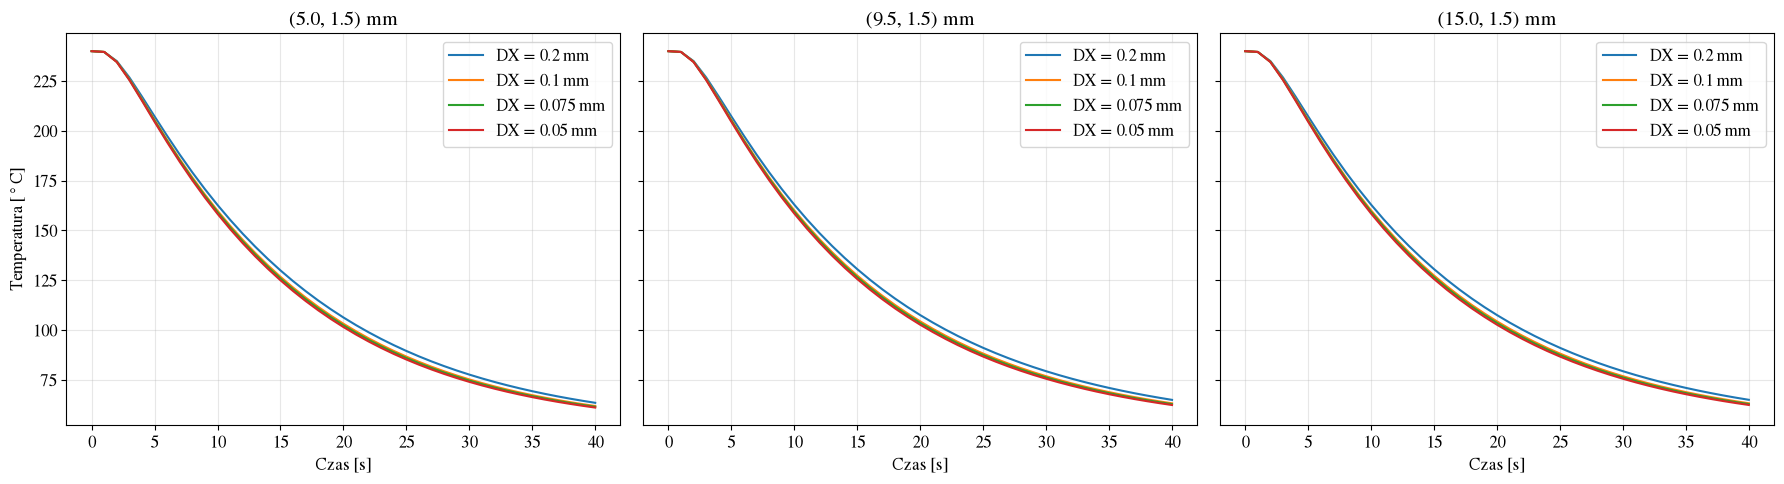

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

for ax, (x, y) in zip(axes, measurement_points):

    for result in results_x:
        temperatures = get_point_temperature(result["frames"], result["dx"], result["dy"], measurement_points)

        point_index = measurement_points.index((x, y))

        ax.plot(result["frame_times"], temperatures[:, point_index], label=f"DX = {result['dx']} mm")

    ax.set_title(f"({x}, {y}) mm")
    ax.set_xlabel("Czas [s]")
    ax.grid(True, alpha=0.3)
    ax.legend()

#fig.suptitle("Zbieżność przestrzenna", y=1.08)
axes[0].set_ylabel(r"Temperatura [$^\circ$C]")

plt.tight_layout()
plt.savefig("figs/spatial.pdf", format="pdf", bbox_inches="tight")
plt.savefig("figs/spatial.svg", format="svg", bbox_inches="tight")
plt.show()

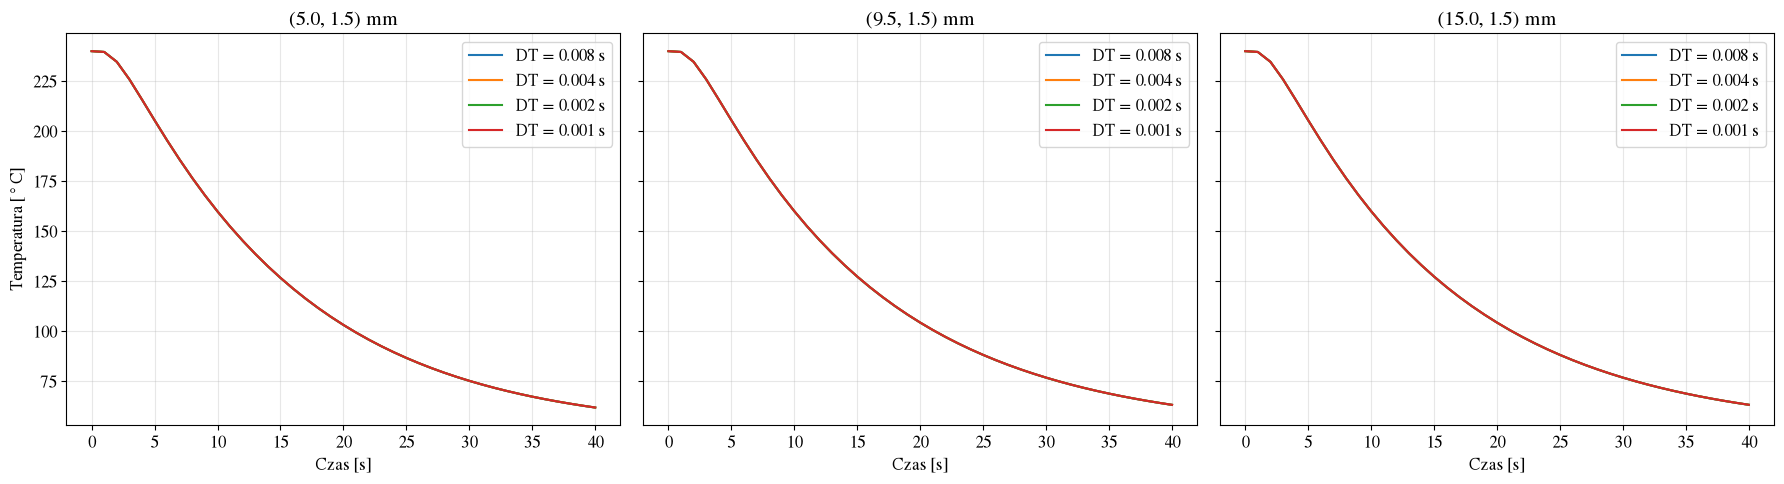

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

for ax, (x, y) in zip(axes, measurement_points):

    for result in results_t:

        temperatures = get_point_temperature(result["frames"], result["dx"], result["dy"], measurement_points)

        point_index = measurement_points.index((x, y))

        ax.plot(result["frame_times"], temperatures[:, point_index], label=f"DT = {result['dt']} s")

    ax.set_title(f"({x}, {y}) mm")
    ax.set_xlabel("Czas [s]")
    ax.grid(True, alpha=0.3)
    ax.legend()

#fig.suptitle("Zbieżność czasowa", y=1.08)
axes[0].set_ylabel(r"Temperatura [$^\circ$C]")

plt.tight_layout()
plt.savefig("figs/temporal.pdf", format="pdf", bbox_inches="tight")
plt.savefig("figs/temporal.svg", format="svg", bbox_inches="tight")
plt.show()